# CS-781 Capstone — Phase 1, v1: Improved Starter Baseline (GPT-2-style decoder)

This is the official starter notebook, **section numbers kept the same**, with:

- an explanation under every step (for the viva), and
- a set of fixes/improvements, each marked **🔧 CHANGE**. The table below is also the "what I changed and why" paragraph for your report.

| #   | Starter did                                             | v1 does                                                                                              | Why                                                                                                                                  |
| --- | ------------------------------------------------------- | ---------------------------------------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------ |
| 1   | Batched generation with **right** padding               | **Left** padding + slice by padded length                                                            | Right padding puts pad (= EOS) tokens _between_ the prompt and the new text, so the model continues after an "end of document" token |
| 2   | Truncates long prompts from the **right**               | Truncates from the **left**                                                                          | If truncation happens, keep the _end_ of the prompt — that's what the continuation must follow                                       |
| 3   | Documents glued together with no separator              | **EOS token after every document**                                                                   | Otherwise the model learns that one judgment flows straight into an unrelated one                                                    |
| 4   | Takes documents in file order                           | **Shuffles documents** first                                                                         | File order may be sorted (year/court); the first 200M tokens may not represent the file                                              |
| 5   | Tokens stored as Python lists of ints (~28+ bytes each) | **NumPy `uint16`** arrays (2 bytes each)                                                             | 200M tokens: roughly 7 GB of RAM → 0.4 GB                                                                                            |
| 6   | `DataCollatorForLanguageModeling`                       | Tiny custom collator                                                                                 | The HF collator turns every pad token into "ignore"; since pad = EOS, it would also hide our new EOS tokens from the loss            |
| 7   | Periodic eval on the full 5M-token val set              | Small eval subset during training, full val set at the end                                           | Evaluating 5M tokens every 1000 steps wastes GPU time                                                                                |
| 8   | Sampling can stop early / repeat itself                 | `min_new_tokens`, `repetition_penalty`, empty-output fallback                                        | The evaluator rejects empty texts; we need ≥128 words                                                                                |
| 9   | No local evaluation                                     | **Held-out local eval set** (512-word prompt + true next 128 words) scored with `evaluate_phase1.py` | Compare ideas locally instead of spending Codabench submissions                                                                      |
| 10  | —                                                       | Experiment log (`experiments.jsonl`), smoke-test switch, pre-submission checks                       | Evidence for the report; catch bugs in minutes, not hours                                                                            |

**Runs on both Kaggle and your laptop** — section 3 detects where it is and sets paths, batch size and precision.

**On your laptop (VS Code):** put this notebook in `notebooks/` and `evaluate_phase1.py` in `scripts/`, select the `.venv` kernel, keep `SMOKE_TEST = True`.

**On Kaggle:** Settings → Accelerator **GPU T4 ×2**, Internet **ON**. Add your HF token as a Kaggle Secret named `HF`.
Upload `evaluate_phase1.py` (Add Input → Upload → new dataset) and set `EVAL_SCRIPT` in section 3.

1. First run with `SMOKE_TEST = True` (≈10–15 min) to make sure every step works.
2. Then set `SMOKE_TEST = False` and use **Save Version → Save & Run All (Commit)**. A committed run keeps going in the background (up to 12 h) even if you close the browser, and everything in `/kaggle/working` is kept as the version's output.


## 1. Hugging Face login

The dataset needs a Hugging Face account. Kaggle _Secrets_ store the token outside the code, so it never appears in your notebook or GitHub repo.
On your laptop there is no Kaggle Secret, so we use the token you already saved with `hf auth login`.


In [1]:
import os
from huggingface_hub import login

try:
    from kaggle_secrets import UserSecretsClient          # exists only on Kaggle
    HF_TOKEN = UserSecretsClient().get_secret("HF")
    login(token="<YOUR_HF_TOKEN>")
except ImportError:                                       # not on Kaggle (your laptop)
    HF_TOKEN = "<YOUR_HF_TOKEN>"                                       # None -> use the token saved by `hf auth login`
    print("Local machine: using the token saved by `hf auth login`.")
print("Hugging Face login successful.")

Local machine: using the token saved by `hf auth login`.
Hugging Face login successful.


## 2. Check GPU

Kaggle "T4 ×2" = two NVIDIA T4 GPUs (16 GB each). T4 supports **fp16** mixed precision (not bf16).
If 2 GPUs are visible, the HF `Trainer` automatically splits each batch across both (`DataParallel`) → effective batch size doubles.


In [2]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 1
GPU 0: NVIDIA GeForce RTX 4050 Laptop GPU


## 3. Configuration

All knobs in one place, so every experiment = "change a few values here + log them".

Important numbers:

- `TRAIN_BLOCK_SIZE = 2048`: each training example is 2048 consecutive tokens. Test input is 512 words ≈ 700–900 GPT-2 tokens, plus ~128 words to generate, so the model must handle ~1100+ positions. 2048 is comfortably enough (we could try 1024 later: faster, and still enough).
- `MIN_NEW_TOKENS`: the model is not allowed to emit EOS before this many new tokens, so we (almost) always get ≥128 words.
- `LOCAL_EVAL_DOCS`: how many held-out documents become our local test set.


In [ ]:
import random, json, time, math, zipfile
import numpy as np

SMOKE_TEST = False         # True = tiny quick run to test the pipeline. Set False for the real run.
RUN_NAME   = "v1_gpt2_560d_8L_sc200M"   # short name used in the experiment log

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TRAIN_FILE = "Phase_1_Pretraining/Train/train_supreme_court.json"
TEST_FILE  = "Phase_1_Pretraining/Test/test.json"

# ---- data ----
TRAIN_TOKENS = 300_000_000   
VAL_TOKENS   = 5_000_000
VAL_FRACTION = 0.05            # 5% of documents go to validation (document-level split -> no leakage)
LOCAL_EVAL_DOCS = 200          # held-out docs turned into (512-word prompt, 128-word truth) pairs
EVAL_BLOCKS_DURING_TRAINING = 250   # 250 x 2048 ≈ 0.5M tokens for the periodic eval
TRAIN_BLOCK_SIZE = 2048
SEED = 42

# ---- model (same as starter: ~59M params) ----
MODEL_CONTEXT_LENGTH = 2048
N_EMBD, N_LAYER, N_HEAD = 560, 8, 8

# ---- training ----
EPOCHS = 1
LR = 3e-4
WARMUP_STEPS = 500

# ---- generation ----
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
MIN_NEW_TOKENS = 200           # ≈ 128 words of legal text needs ~170-200 GPT-2 tokens
DO_SAMPLE = True
TEMPERATURE = 0.1
TOP_P = 0.95
REPETITION_PENALTY = 1.1       # >1 makes already-used tokens less likely (1.0 = off)
GENERATION_BATCH_SIZE = 32

if SMOKE_TEST:
    TRAIN_TOKENS, VAL_TOKENS, LOCAL_EVAL_DOCS = 2_000_000, 200_000, 16
    EVAL_BLOCKS_DURING_TRAINING = 20
    WARMUP_STEPS = 20
    RUN_NAME += "_SMOKE"

# ---- machine-specific settings: the same notebook runs on Kaggle and on your laptop ----
ON_KAGGLE = os.path.exists("/kaggle")
if ON_KAGGLE:
    from pathlib import Path
    PROJECT_ROOT = Path.cwd()
    while not (PROJECT_ROOT / ".gitignore").exists():     # walk up until the project folder
        PROJECT_ROOT = PROJECT_ROOT.parent
    OUTPUT_DIR  = str(PROJECT_ROOT / "checkpoints" / "phase1")
    EVAL_SCRIPT = str(PROJECT_ROOT / "scripts" / "evaluate_phase1.py")
    PER_DEVICE_BATCH, GRAD_ACCUM = 4, 2    # T4 has 16 GB
    NUM_WORKERS = 2
else:
    from pathlib import Path
    PROJECT_ROOT = Path.cwd()
    while not (PROJECT_ROOT / ".gitignore").exists():     # walk up until the project folder
        PROJECT_ROOT = PROJECT_ROOT.parent
    OUTPUT_DIR  = str(PROJECT_ROOT / "checkpoints" / "phase1")
    EVAL_SCRIPT = str(PROJECT_ROOT / "scripts" / "evaluate_phase1.py")
    PER_DEVICE_BATCH, GRAD_ACCUM = 1, 8    # RTX 4050 has 6 GB: smaller micro-batch, more accumulation
    NUM_WORKERS = 0                        # Windows + notebooks: worker processes can't import notebook-defined classes
# bf16 if the GPU supports it (RTX 40xx: yes, T4: no -> fp16)
USE_BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
print("On Kaggle:", ON_KAGGLE, "| bf16:", USE_BF16, "| output:", OUTPUT_DIR)

MODEL_OUTPUT_DIR = os.path.join(OUTPUT_DIR, RUN_NAME)
PREDICTION_PATH  = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP   = os.path.join(OUTPUT_DIR, "submission.zip")
LOSS_PLOT_PATH   = os.path.join(OUTPUT_DIR, f"{RUN_NAME}_loss.png")
_sfx = "_smoke" if SMOKE_TEST else ""
VAL_PROMPTS_PATH = os.path.join(OUTPUT_DIR, f"local_eval_prompts{_sfx}.json")
VAL_TRUTH_PATH   = os.path.join(OUTPUT_DIR, f"local_eval_truth{_sfx}.json")
EXPERIMENT_LOG   = os.path.join(OUTPUT_DIR, "experiments.jsonl")
os.makedirs(OUTPUT_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)   # reproducibility
print("Configuration loaded. SMOKE_TEST =", SMOKE_TEST)

On Kaggle: False | bf16: True | output: c:\Users\Atharva\Desktop\Assignments\LLM\Capstone Project\checkpoints\phase1
Configuration loaded. SMOKE_TEST = False


## 4. Tokenizer

We use the GPT-2 **BPE tokenizer** (only the tokenizer — no pretrained weights; that's allowed).
BPE (Byte-Pair Encoding) starts from bytes and repeatedly merges the most frequent adjacent pair into a new token, until the vocabulary has 50,257 entries.
Frequent words become one token ("court"), rare words are split into pieces ("respond", "ent").

GPT-2 has no padding token, so we reuse EOS (`<|endoftext|>`, id 50256) as padding.

🔧 **CHANGE 1 & 2:** `padding_side="left"` and `truncation_side="left"` (explained in section 19).
`model_max_length` is raised only to silence a harmless warning when we tokenize whole long judgments for training (we cut them into blocks ourselves).


In [4]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "left"        # 🔧 CHANGE 1
tokenizer.truncation_side = "left"     # 🔧 CHANGE 2
tokenizer.model_max_length = 10**9     # we handle lengths ourselves
EOS_ID = tokenizer.eos_token_id
print("Vocabulary size:", len(tokenizer), "| EOS id:", EOS_ID)
print("Example:", tokenizer.tokenize("The appellant filed a writ petition under Article 226."))

c:\Users\Atharva\Desktop\Assignments\LLM\Capstone Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Vocabulary size: 50257 | EOS id: 50256
Example: ['The', 'Ġappellant', 'Ġfiled', 'Ġa', 'Ġwrit', 'Ġpetition', 'Ġunder', 'ĠArticle', 'Ġ226', '.']


## 5. Download training data

`hf_hub_download` downloads the file once into a local cache and returns its path. The Supreme Court file is a few GB.


In [5]:
from huggingface_hub import hf_hub_download

train_file_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename=TRAIN_FILE,
                                  repo_type="dataset", token=HF_TOKEN)
print("Training file:", train_file_path, f"({os.path.getsize(train_file_path)/1e9:.2f} GB)")

Training file: C:\Users\Atharva\.cache\huggingface\hub\datasets--Exploration-Lab--CS-781-Capstone\snapshots\89edba6a44d6bb9593fd13b6895b5cd3b06eb82e\Phase_1_Pretraining\Train\train_supreme_court.json (1.32 GB)


In [6]:
from huggingface_hub import HfApi

local_size = os.path.getsize(train_file_path)          # size of the file on your laptop, in bytes
server_info = HfApi().get_paths_info(HF_DATASET_REPO, TRAIN_FILE, repo_type="dataset")
server_size = server_info[0].size                      # size of the same file on Hugging Face

print("Path       :", train_file_path)
print(f"Local size : {local_size / 1e9:.3f} GB")
print(f"Server size: {server_size / 1e9:.3f} GB")
print("Complete download:", local_size == server_size)

with open(train_file_path, "rb") as f:                 # "rb" = read raw bytes
    f.seek(-200, 2)                                    # jump to 200 bytes before the END of the file
    print("Last bytes:", f.read())

Path       : C:\Users\Atharva\.cache\huggingface\hub\datasets--Exploration-Lab--CS-781-Capstone\snapshots\89edba6a44d6bb9593fd13b6895b5cd3b06eb82e\Phase_1_Pretraining\Train\train_supreme_court.json
Local size : 1.323 GB
Server size: 1.323 GB
Complete download: True
Last bytes: b'. However, in the facts of the case, there shall be no orders as to costs.\\n\\nJ. [DR. B.S. CHAUHAN]\\n\\nJ. [SWATANTER KUMAR] New Delhi July 8, 2010.", "word_count": 6734, "text_length_chars": 39560}\n]\n'


## 6. Build train / validation tokens + the local eval set

What happens here:

1. `json.load` the file → a Python list of `{"text": ...}` records. (OK for the SC file on Kaggle's ~30 GB RAM; for the larger files we'll stream later.)
2. 🔧 **CHANGE 4:** shuffle the documents with a fixed seed → a representative sample, and the same one every run.
3. Each document goes **entirely** to train (95%) or validation (5%). Splitting by _document_ (not by token) means no judgment is half in train, half in val — otherwise validation loss would be too optimistic.
4. 🔧 **CHANGE 3:** append EOS after every document, so the model sees document boundaries.
5. 🔧 **CHANGE 5:** store token ids as `np.uint16` (0–65,535; our largest id is 50,256) → 2 bytes per token.
6. 🔧 **CHANGE 9:** some long validation documents (≥ 700 words) are also kept as raw text → local eval set in section 6b.

We tokenize **256 documents per call**: the HF "fast" tokenizer is written in Rust and processes a list in parallel, much faster than one `encode` per document.


In [7]:
with open(train_file_path, "r", encoding="utf-8") as f:
    records = json.load(f)
print(f"Documents in file: {len(records):,}")

rng = random.Random(SEED)
rng.shuffle(records)                                    # 🔧 CHANGE 4

train_chunks, val_chunks = [], []                       # lists of per-document uint16 arrays
n_train = n_val = 0
local_eval_texts = []
BATCH_DOCS = 256
t0 = time.time()

for start in range(0, len(records), BATCH_DOCS):
    texts = [r["text"] for r in records[start:start + BATCH_DOCS] if r.get("text")]
    is_val = [rng.random() < VAL_FRACTION for _ in texts]
    ids_list = tokenizer(texts, add_special_tokens=False)["input_ids"]   # batched, Rust-parallel

    for text, ids, v in zip(texts, ids_list, is_val):
        ids = np.array(ids + [EOS_ID], dtype=np.uint16)                  # 🔧 CHANGE 3 + 5
        if v:
            if len(local_eval_texts) < LOCAL_EVAL_DOCS and len(text.split()) >= 700:
                local_eval_texts.append(text)
            if n_val < VAL_TOKENS:
                ids = ids[:VAL_TOKENS - n_val]
                val_chunks.append(ids); n_val += len(ids)
        else:
            if n_train < TRAIN_TOKENS:
                ids = ids[:TRAIN_TOKENS - n_train]
                train_chunks.append(ids); n_train += len(ids)

    if n_train >= TRAIN_TOKENS and n_val >= VAL_TOKENS and len(local_eval_texts) >= LOCAL_EVAL_DOCS:
        break

train_ids = np.concatenate(train_chunks); val_ids = np.concatenate(val_chunks)
del records, train_chunks, val_chunks                   # free RAM
print(f"Train tokens: {len(train_ids):,} | Val tokens: {len(val_ids):,} | "
      f"local eval docs: {len(local_eval_texts)} | {time.time()-t0:.0f}s")

Documents in file: 55,549
Train tokens: 257,755,683 | Val tokens: 5,000,000 | local eval docs: 200 | 502s


## 6b. Local evaluation set (🔧 CHANGE 9)

We imitate the official test: from each held-out document take **512 consecutive words as the prompt** and the **next 128 words as the truth**.
The start position is random (seeded), so prompts don't all begin at the case title.

Formats match the official ones exactly, so `evaluate_phase1.py` can score them:
`{"0": {"text": prompt}, ...}` and `{"0": {"text": truth}, ...}`.

⚠️ Every experiment and every architecture must be scored on the **same** set, otherwise scores aren't comparable.
With the same `SEED` and the same `TRAIN_FILE`, this cell rebuilds exactly the same set every run (same shuffle → same validation documents). Still, download the two files from the Output tab and keep them.
When you later change the data (other files, different split), these documents must stay out of training.


In [8]:
def make_eval_pair(text, rng, prompt_words=512, cont_words=128):
    words = text.split()
    start = rng.randint(0, len(words) - (prompt_words + cont_words))   # random start that still fits
    prompt = " ".join(words[start : start + prompt_words])
    truth  = " ".join(words[start + prompt_words : start + prompt_words + cont_words])
    return prompt, truth

eval_rng = random.Random(SEED)
val_prompts, val_truth = {}, {}
for i, text in enumerate(local_eval_texts):
    p, t = make_eval_pair(text, eval_rng)
    val_prompts[str(i)] = {"text": p}
    val_truth[str(i)]   = {"text": t}
json.dump(val_prompts, open(VAL_PROMPTS_PATH, "w", encoding="utf-8"), ensure_ascii=False)
json.dump(val_truth,   open(VAL_TRUTH_PATH,   "w", encoding="utf-8"), ensure_ascii=False)
print("Saved", len(val_prompts), "local eval pairs")
print("Example truth:", val_truth["0"]["text"][:200], "...")

Saved 200 local eval pairs
Example truth: which the suit is pending. In the second place, the order does not put an end to the suit which remains perfectly alive and that very suit is to be tried by another court, the proceedings in the latte ...


## 7. Cut the token stream into blocks

A language model trains on fixed-length windows. We cut the long 1-D token array into rows of 2048: `reshape(n_blocks, 2048)`.
The leftover tokens at the end (fewer than 2048) are dropped. A block can contain the end of one judgment, EOS, and the start of the next — that's normal ("packing"), and EOS tells the model where the boundary is.


In [9]:
def to_blocks(arr, block_size):
    n_blocks = len(arr) // block_size
    return arr[: n_blocks * block_size].reshape(n_blocks, block_size)   # a view, no copy

train_blocks = to_blocks(train_ids, TRAIN_BLOCK_SIZE)
val_blocks   = to_blocks(val_ids, TRAIN_BLOCK_SIZE)
print("Training sequences:", train_blocks.shape, "| Validation sequences:", val_blocks.shape)

Training sequences: (125857, 2048) | Validation sequences: (2441, 2048)


## 8. Dataset + collator (🔧 CHANGE 5 & 6)

A PyTorch `Dataset` only needs `__len__` (how many examples) and `__getitem__` (return example _i_).
We convert a row to `int64` only when it's requested, because the embedding layer needs `LongTensor` indices, but storing everything as int64 would take 4× the RAM.

The **collator** turns a list of examples into one batch. For causal LM, `labels = input_ids`.
We do **not** shift labels by one here — `GPT2LMHeadModel` does that internally: position _t_ predicts token _t+1_.


In [10]:
class BlockDataset(torch.utils.data.Dataset):
    def __init__(self, blocks):
        self.blocks = blocks
    def __len__(self):
        return len(self.blocks)
    def __getitem__(self, i):
        return {"input_ids": torch.from_numpy(self.blocks[i].astype(np.int64))}

def collate(batch):
    input_ids = torch.stack([ex["input_ids"] for ex in batch])   # (batch, 2048)
    return {"input_ids": input_ids, "labels": input_ids.clone()}  # model shifts labels internally

train_dataset = BlockDataset(train_blocks)
val_dataset_small = BlockDataset(val_blocks[:EVAL_BLOCKS_DURING_TRAINING])   # 🔧 CHANGE 7
val_dataset_full  = BlockDataset(val_blocks)
print(len(train_dataset), len(val_dataset_small), len(val_dataset_full))

125857 250 2441


## 9. The model: GPT-2-style decoder-only Transformer (random init)

`GPT2Config` describes the architecture; `GPT2LMHeadModel(config)` builds it with **random weights** (we never call `from_pretrained` for the model — that's what "from scratch" means).

Structure: token embedding + learned position embedding → 8 identical blocks, each = LayerNorm → causal multi-head self-attention → residual add → LayerNorm → MLP (560 → 2240 → 560, GELU) → residual add → final LayerNorm → LM head (vocab logits).
"Causal" = each position can only attend to earlier positions, so the model can't cheat by looking at the token it must predict.

**Parameter count, by hand** (d = 560, V = 50,257, L = 8):

- token embeddings V·d ≈ 28.1M, position embeddings 2048·d ≈ 1.1M
- each block ≈ 12·d² ≈ 3.76M (attention 4d², MLP 8d²) → 8 blocks ≈ 30.1M
- LM head: **shares** the token-embedding matrix ("weight tying") → 0 extra
- total ≈ **59M**. Nearly half is the embedding table! A smaller legal-specific vocabulary would move parameters into the Transformer blocks — an experiment for later.


In [11]:
from transformers import GPT2Config, GPT2LMHeadModel

config = GPT2Config(
    vocab_size=len(tokenizer),
    n_positions=MODEL_CONTEXT_LENGTH,
    n_embd=N_EMBD, n_layer=N_LAYER, n_head=N_HEAD,
    bos_token_id=EOS_ID, eos_token_id=EOS_ID,
)
model = GPT2LMHeadModel(config)

total  = sum(p.numel() for p in model.parameters())      # tied weights are counted once
emb    = model.transformer.wte.weight.numel()
pos    = model.transformer.wpe.weight.numel()
blocks = sum(p.numel() for p in model.transformer.h.parameters())
print(f"Total: {total/1e6:.2f}M | token emb: {emb/1e6:.2f}M | pos emb: {pos/1e6:.2f}M | blocks: {blocks/1e6:.2f}M")
assert 50e6 <= total <= 300e6, "Model outside the allowed 50M-300M range!"

Total: 59.46M | token emb: 28.14M | pos emb: 1.15M | blocks: 30.16M


## 10. Training arguments

- **Effective batch** = per-device batch × grad accumulation × #GPUs × 2048 tokens. Kaggle: 4 × 2 × 2 × 2048 ≈ 33k tokens per step. Laptop: 2 × 4 × 1 × 2048 ≈ 16k.
- **Gradient accumulation**: run 2 small batches, add up their gradients, then do one update — a bigger batch without more GPU memory.
- **Warmup + cosine**: LR rises linearly from 0 to 3e-4 over 500 steps (random weights give huge, noisy gradients at the start), then decays along a cosine curve toward 0.
- **Weight decay 0.1** (AdamW): shrinks weights slightly every step → regularization.
- **bf16 / fp16** (mixed precision): most math in 16-bit floats → ~2× faster, half the activation memory. bf16 (RTX 40xx) has the same _range_ as fp32, so it's stable as is; fp16 (T4) has a small range, so a "loss scaler" multiplies the loss to stop tiny gradients from rounding to zero.
- **save_steps**: checkpoints every 1000 steps, so a crash doesn't lose everything (`save_total_limit=2` keeps disk usage small).


In [12]:
from transformers import TrainingArguments, Trainer

n_gpu = max(torch.cuda.device_count(), 1)
tokens_per_step = PER_DEVICE_BATCH * GRAD_ACCUM * n_gpu * TRAIN_BLOCK_SIZE
total_steps = len(train_dataset) * EPOCHS // (PER_DEVICE_BATCH * GRAD_ACCUM * n_gpu)
print(f"Tokens per optimizer step: {tokens_per_step:,} | total steps ≈ {total_steps:,}")

training_args = TrainingArguments(
    output_dir=MODEL_OUTPUT_DIR,
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=PER_DEVICE_BATCH,
    per_device_eval_batch_size=PER_DEVICE_BATCH,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=LR,
    weight_decay=0.1,
    warmup_steps=WARMUP_STEPS,
    lr_scheduler_type="cosine",
    max_grad_norm=1.0,                  # gradient clipping: cap the gradient size -> no sudden huge updates
    bf16=USE_BF16,                                     # RTX 40xx
    fp16=torch.cuda.is_available() and not USE_BF16,   # T4 fallback
    eval_strategy="steps",
    eval_steps=2000 if not SMOKE_TEST else 20,
    optim="adamw_torch_fused", 
    logging_steps=2000 if not SMOKE_TEST else 5,
    save_steps=2000 if not SMOKE_TEST else 20,
    save_total_limit=2,
    dataloader_num_workers=NUM_WORKERS,
    seed=SEED,
    report_to="none",
)

Tokens per optimizer step: 16,384 | total steps ≈ 15,732


## 11. Training

`Trainer` runs the loop for us: for each batch → forward pass → loss (cross-entropy of next-token prediction) → backward pass (gradients) → optimizer step → LR scheduler step; plus logging, evaluation and checkpointing.

To **resume** after a crash: `trainer.train(resume_from_checkpoint=True)` continues from the latest checkpoint in `output_dir`.


In [30]:
import glob

FORCE_RETRAIN = False     # set True only if you deliberately want to train again
final_model_file = os.path.join(MODEL_OUTPUT_DIR, "model.safetensors")
ALREADY_TRAINED = os.path.exists(final_model_file) and not FORCE_RETRAIN

if ALREADY_TRAINED:
    print("Finished model found -> loading it, NOT training:", MODEL_OUTPUT_DIR)
    model = GPT2LMHeadModel.from_pretrained(MODEL_OUTPUT_DIR)   # replaces the random model from section 9
else:
    print("No finished model -> training from scratch.")

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset_small,
    data_collator=collate,
)

if ALREADY_TRAINED:
    # Restore the loss history from the newest checkpoint, so section 13 can still draw the plot
    ckpts = sorted(glob.glob(os.path.join(MODEL_OUTPUT_DIR, "checkpoint-*")),
                   key=lambda p: int(p.rsplit("-", 1)[1]))       # sort by step number, not alphabetically
    if ckpts:
        with open(os.path.join(ckpts[-1], "trainer_state.json")) as f:
            trainer.state.log_history = json.load(f)["log_history"]
        print("Loss history restored from", os.path.basename(ckpts[-1]))
    training_time = None                                         # unknown in this session
else:
    start_time = time.time()
    trainer.train()
    training_time = time.time() - start_time
    tokens_seen = len(train_dataset) * TRAIN_BLOCK_SIZE * EPOCHS
    print(f"Training time: {training_time/3600:.2f} h | speed: {tokens_seen/training_time:,.0f} tokens/s")

Finished model found -> loading it, NOT training: c:\Users\Atharva\Desktop\Assignments\LLM\Capstone Project\checkpoints\phase1\v1_gpt2_560d_8L_sc200M


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 852.50it/s]


Loss history restored from checkpoint-15733


## 12. Validation loss and perplexity (full validation set)

Loss = average cross-entropy = average of −log P(correct next token).
**Perplexity = e^loss**: "on average the model is as unsure as if it picked uniformly among this many tokens". Lower is better.
Perplexity is only comparable between models with the **same tokenizer** (different tokenizers split text differently).


In [31]:
VAL_RESULTS_FILE = os.path.join(MODEL_OUTPUT_DIR, "val_results.json")

if ALREADY_TRAINED and os.path.exists(VAL_RESULTS_FILE):
    with open(VAL_RESULTS_FILE) as f:
        saved = json.load(f)
    val_loss, perplexity = saved["val_loss"], saved["perplexity"]
    print("Loaded saved validation results (no re-evaluation).")
else:
    eval_results = trainer.evaluate(eval_dataset=val_dataset_full)
    trainer.state.log_history.pop()
    val_loss = eval_results["eval_loss"]
    perplexity = math.exp(val_loss)
    with open(VAL_RESULTS_FILE, "w") as f:
        json.dump({"val_loss": val_loss, "perplexity": perplexity}, f, indent=2)
    print("Saved validation results to", VAL_RESULTS_FILE)

print(f"Validation loss: {val_loss:.4f} | perplexity: {perplexity:.2f}")

Loaded saved validation results (no re-evaluation).
Validation loss: 2.6009 | perplexity: 13.48


## 13. Plot training and validation loss

What to look for: both curves going down together = still learning (more data/steps would help). Validation going _up_ while training goes down = overfitting.
With 1 epoch over fresh data, overfitting is unlikely.


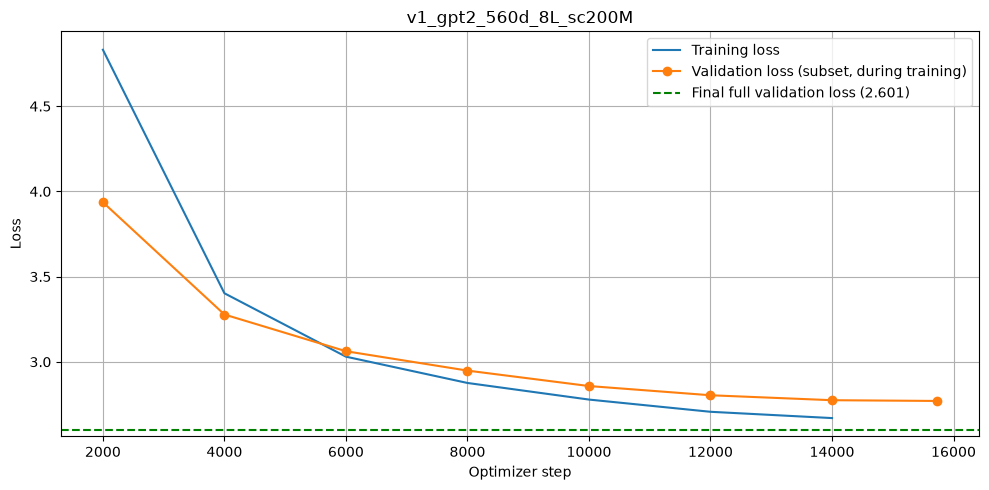

In [32]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history
tr = [(l["step"], l["loss"]) for l in logs if "loss" in l]
ev = [(l["step"], l["eval_loss"]) for l in logs if "eval_loss" in l]
plt.figure(figsize=(10, 5))
plt.plot(*zip(*tr), label="Training loss")
if ev: plt.plot(*zip(*ev), marker="o", label="Validation loss (subset, during training)")
plt.axhline(val_loss, color="green", linestyle="--", label=f"Final full validation loss ({val_loss:.3f})")
plt.xlabel("Optimizer step"); plt.ylabel("Loss"); plt.title(RUN_NAME)
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200); plt.show()

## 14. Save the final model

Saves weights (`model.safetensors`) + `config.json` + tokenizer files. You need these for **every later phase** and for the viva — download them or keep them as a Kaggle dataset.


In [29]:
if ALREADY_TRAINED:
    print("Model already saved - nothing to do.")
else:
    trainer.save_model(MODEL_OUTPUT_DIR)
    tokenizer.save_pretrained(MODEL_OUTPUT_DIR)
    print("Saved to", MODEL_OUTPUT_DIR)

Model already saved - nothing to do.


In [33]:
import gc

del trainer, model              # remove the training objects (weights, gradients, optimizer state)
gc.collect()                    # Python's garbage collector: actually frees the deleted objects
torch.cuda.empty_cache()        # give PyTorch's reserved-but-unused GPU memory back

GENERATION_BATCH_SIZE = 8       # laptop: 8 prompts at a time instead of 32 (fits in 6 GB)
print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

GPU memory in use: 0.26 GB


## 15–18. Load test prompts and the model for generation


In [34]:
test_file_path = hf_hub_download(repo_id=HF_DATASET_REPO, filename=TEST_FILE,
                                 repo_type="dataset", token=HF_TOKEN)
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print("Number of test examples:", len(test_data))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
gen_model = GPT2LMHeadModel.from_pretrained(MODEL_OUTPUT_DIR).to(device)
gen_model.eval()                       # turns off dropout
gen_tokenizer = AutoTokenizer.from_pretrained(MODEL_OUTPUT_DIR)
gen_tokenizer.padding_side = "left"; gen_tokenizer.truncation_side = "left"
print(f"Parameters: {sum(p.numel() for p in gen_model.parameters())/1e6:.2f}M on {device}")

Number of test examples: 1000


Loading weights: 100%|██████████| 100/100 [00:00<00:00, 757.01it/s]


Parameters: 59.46M on cuda


In [35]:
# All vocabulary tokens that are ONLY whitespace and contain a line break (e.g. "\n", "\n\n", " \n")
NEWLINE_TOKEN_IDS = [i for i in range(len(gen_tokenizer))
                     if "\n" in gen_tokenizer.decode([i]) and gen_tokenizer.decode([i]).strip() == ""]
print(len(NEWLINE_TOKEN_IDS), "newline tokens:", NEWLINE_TOKEN_IDS[:10])

3 newline tokens: [198, 628, 44320]


## 19. Generate 128 words (🔧 CHANGES 1, 2, 8)

**Why left padding?** A batch needs equal-length rows, so shorter prompts get pad tokens.

- Right padding: `[prompt A ...][pad pad]` → generation starts _after the pads_. Since pad = EOS, the model continues after an "end of document" signal → worse text. (Transformers even prints a warning about this.)
- Left padding: `[pad pad][prompt A ...]` → every prompt ends exactly where generation starts. The attention mask tells the model to ignore the pads.

With left padding, all prompts in the batch end at the same column (`prompt_len`), so the new tokens are simply `out[:, prompt_len:]`.

**Decoding settings:**

- `do_sample=True, temperature=0.1`: sample from the next-token distribution after sharpening it (low temperature ≈ almost greedy).
- `top_p=0.95` (nucleus sampling): only sample among the most likely tokens whose probabilities add up to 95%.
- `repetition_penalty=1.1`: divides the score of already-generated tokens → fewer loops like "the court the court the court".
- `min_new_tokens`: EOS is blocked until this many tokens exist.

Then we cut to exactly 128 **words** (whitespace split), because the task counts words, not tokens.


In [36]:
def generate_batch(prompts, model, tokenizer, gen_cfg, target_words=TARGET_GENERATION_WORDS):
    inputs = tokenizer(prompts, return_tensors="pt", padding=True, truncation=True,
                       max_length=MODEL_CONTEXT_LENGTH - MAX_GENERATION_TOKENS)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    prompt_len = inputs["input_ids"].shape[1]          # same for every row thanks to left padding

    with torch.inference_mode():                       # no gradients -> faster, less memory
        out = model.generate(**inputs, max_new_tokens=MAX_GENERATION_TOKENS,
                             min_new_tokens=MIN_NEW_TOKENS,
                             pad_token_id=tokenizer.eos_token_id, **gen_cfg)

    texts = tokenizer.batch_decode(out[:, prompt_len:], skip_special_tokens=True)
    preds = []
    for t in texts:
        words = t.split()[:target_words]
        preds.append(" ".join(words) if words else "the")   # evaluator rejects empty text
    return preds

def make_gen_cfg(do_sample=DO_SAMPLE, temperature=TEMPERATURE, top_p=TOP_P, repetition_penalty=REPETITION_PENALTY):
    cfg = {"do_sample": do_sample, "repetition_penalty": repetition_penalty,
           "suppress_tokens": NEWLINE_TOKEN_IDS}        # never generate line-break-only tokens
    if do_sample:                                      # temperature/top_p only matter when sampling
        cfg.update(temperature=temperature, top_p=top_p)
    return cfg

def predict_all(prompt_dict, gen_cfg, limit=None):
    items = list(prompt_dict.items())[:limit]
    preds = {}
    for s in range(0, len(items), GENERATION_BATCH_SIZE):
        batch = items[s:s + GENERATION_BATCH_SIZE]
        outs = generate_batch([r["text"] for _, r in batch], gen_model, gen_tokenizer, gen_cfg)
        for (eid, _), p in zip(batch, outs):
            preds[str(eid)] = {"text": p}
        print(f"\r{min(s + GENERATION_BATCH_SIZE, len(items))}/{len(items)}", end="")
    print()
    return preds

## 19b. Local evaluation (🔧 CHANGE 9)

Generate for our held-out prompts, then run the organisers' `evaluate_phase1.py` exactly as it runs on Codabench (same metrics code), and read the three numbers from its output.

The metrics in one line each:

- **BERTScore F1** (primary): embeds both texts with a pretrained RoBERTa-large _evaluator_ and matches each word to its most similar word in the other text → rewards _meaning_ overlap, not exact wording. Values sit around 0.8 even for mediocre text, so differences between models are small (0.01 is a real gain).
- **ROUGE-L F1**: longest common subsequence of words (in order, gaps allowed).
- **BLEU-4**: exact overlap of 1- to 4-word sequences over the whole set; becomes 0 if there is no 4-gram match at all.

The small **decoding sweep** compares a few settings on the _same_ model — cheap experiments that often move the score.


In [37]:
import subprocess, sys

def run_local_eval(pred_path, truth_path=VAL_TRUTH_PATH):
    # sys.executable = the exact Python running this notebook (.venv), not whatever "python" Windows finds first
    env = dict(os.environ, PYTHONUTF8="1")   # make the child Python read/write UTF-8 (Windows default is cp1252)
    r = subprocess.run([sys.executable, EVAL_SCRIPT, "--truth", truth_path, "--prediction", pred_path],
                       capture_output=True, text=True, encoding="utf-8", errors="replace", env=env)
    if r.returncode != 0:
        print(r.stderr); return None
    scores = {}
    for line in r.stdout.splitlines():
        key, _, val = line.partition(":")
        if key.strip() in ("BERTScore F1", "ROUGE-L F1", "BLEU-4"):
            scores[key.strip()] = float(val)
    return scores

val_prompts = json.load(open(VAL_PROMPTS_PATH, encoding="utf-8"))

sweep = {
    "starter_like (T=0.1, no rep. penalty)": make_gen_cfg(repetition_penalty=1.0),
    "T=0.1 + rep 1.1":                       make_gen_cfg(),
    "greedy + rep 1.1":                      make_gen_cfg(do_sample=False),
}
LOCAL_RESULTS_FILE = os.path.join(MODEL_OUTPUT_DIR, "local_eval_results.json")

def results_from_log(run_name):
    # Find this run's local_eval results in experiments.jsonl (for runs logged before this file existed)
    found = None
    if os.path.exists(EXPERIMENT_LOG):
        with open(EXPERIMENT_LOG) as f:
            for line in f:
                entry = json.loads(line)
                if entry.get("run") == run_name and entry.get("local_eval"):
                    found = entry["local_eval"]          # keep the newest matching entry
    return found

local_results = results_from_log(RUN_NAME) if ALREADY_TRAINED else None
if ALREADY_TRAINED and os.path.exists(LOCAL_RESULTS_FILE):
    with open(LOCAL_RESULTS_FILE) as f:
        local_results = json.load(f)

if local_results:
    print("Loaded saved local evaluation results (no regeneration):")
    for name, scores in local_results.items():
        print(" ", name, "->", scores)
else:
    local_results = {}
    for name, cfg in sweep.items():
        preds = predict_all(val_prompts, cfg)
        path = os.path.join(OUTPUT_DIR, "local_pred.json")
        json.dump(preds, open(path, "w", encoding="utf-8"), ensure_ascii=False)
        local_results[name] = run_local_eval(path)
        print(name, "->", local_results[name])

with open(LOCAL_RESULTS_FILE, "w") as f:
    json.dump(local_results, f, indent=2)

Loaded saved local evaluation results (no regeneration):
  starter_like (T=0.1, no rep. penalty) -> {'BERTScore F1': 0.808573, 'ROUGE-L F1': 0.189752, 'BLEU-4': 0.037165}
  T=0.1 + rep 1.1 -> {'BERTScore F1': 0.811874, 'ROUGE-L F1': 0.181227, 'BLEU-4': 0.037314}
  greedy + rep 1.1 -> {'BERTScore F1': 0.809311, 'ROUGE-L F1': 0.177243, 'BLEU-4': 0.035145}


## 19c. Log the experiment

One JSON line per run. At the end of Phase 1 this file becomes the results table in your report.


In [38]:
log_entry = {
    "run": RUN_NAME, "time": time.strftime("%Y-%m-%d %H:%M"),
    "train_file": TRAIN_FILE, "train_tokens": int(len(train_ids)),
    "params_M": round(total / 1e6, 2), "n_embd": N_EMBD, "n_layer": N_LAYER, "n_head": N_HEAD,
    "block": TRAIN_BLOCK_SIZE, "lr": LR, "tokens_per_step": tokens_per_step,
    "train_hours": round(training_time / 3600, 2) if training_time else None,
    "val_loss": round(val_loss, 4), "val_ppl": round(perplexity, 2),
    "local_eval": local_results,
}
with open(EXPERIMENT_LOG, "a") as f:
    f.write(json.dumps(log_entry) + "\n")
print(json.dumps(log_entry, indent=2))

{
  "run": "v1_gpt2_560d_8L_sc200M",
  "time": "2026-09-25 19:37",
  "train_file": "Phase_1_Pretraining/Train/train_supreme_court.json",
  "train_tokens": 257755683,
  "params_M": 59.46,
  "n_embd": 560,
  "n_layer": 8,
  "n_head": 8,
  "block": 2048,
  "lr": 0.0003,
  "tokens_per_step": 16384,
  "train_hours": null,
  "val_loss": 2.6009,
  "val_ppl": 13.48,
  "local_eval": {
    "starter_like (T=0.1, no rep. penalty)": {
      "BERTScore F1": 0.808573,
      "ROUGE-L F1": 0.189752,
      "BLEU-4": 0.037165
    },
    "T=0.1 + rep 1.1": {
      "BERTScore F1": 0.811874,
      "ROUGE-L F1": 0.181227,
      "BLEU-4": 0.037314
    },
    "greedy + rep 1.1": {
      "BERTScore F1": 0.809311,
      "ROUGE-L F1": 0.177243,
      "BLEU-4": 0.035145
    }
  }
}


## 20–22. Test predictions → checks → submission.zip

Pick the decoding setting that won locally, generate for all official test prompts, then **check before zipping**: same IDs as the test file, no empty texts, word counts.
In smoke-test mode we only generate a few and skip the zip.


In [39]:
RUN_PREDICTION_PATH = os.path.join(MODEL_OUTPUT_DIR, "prediction.json")   # per-run files
RUN_SUBMISSION_ZIP  = os.path.join(MODEL_OUTPUT_DIR, "submission.zip")

if ALREADY_TRAINED and os.path.exists(RUN_SUBMISSION_ZIP):
    print("Submission already exists for this run - skipping generation:", RUN_SUBMISSION_ZIP)
else:
    best_name = max(local_results, key=lambda n: (local_results[n] or {}).get("BERTScore F1", -1))
    best_cfg = sweep[best_name]
    print("Using decoding:", best_name)

    predictions = predict_all(test_data, best_cfg, limit=64 if SMOKE_TEST else None)

    wc = [len(p["text"].split()) for p in predictions.values()]
    print(f"words per prediction: min={min(wc)} mean={np.mean(wc):.1f} max={max(wc)} | "
          f"<128 words: {sum(w < 128 for w in wc)}")

    if not SMOKE_TEST:
        assert set(predictions) == set(map(str, test_data)), "ID mismatch with the test file!"
        assert all(p["text"].strip() for p in predictions.values()), "Empty prediction found!"
        with open(RUN_PREDICTION_PATH, "w", encoding="utf-8") as f:
            json.dump(predictions, f, ensure_ascii=False, indent=2)
        with zipfile.ZipFile(RUN_SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as z:
            z.write(RUN_PREDICTION_PATH, arcname="prediction.json")
        print(zipfile.ZipFile(RUN_SUBMISSION_ZIP).namelist(), "->", RUN_SUBMISSION_ZIP)

Submission already exists for this run - skipping generation: c:\Users\Atharva\Desktop\Assignments\LLM\Capstone Project\checkpoints\phase1\v1_gpt2_560d_8L_sc200M\submission.zip


In [41]:
# Load the predictions we just submitted (works even if the kernel was restarted)
with open(RUN_PREDICTION_PATH, encoding="utf-8") as f:
    submitted = json.load(f)

short = [(k, v["text"]) for k, v in submitted.items() if len(v["text"].split()) < 128]
print(f"{len(short)} short predictions\n")

for k, text in short:
    words = text.split()
    longest = max(words, key=len)                 # the longest "word" (a no-space run would show up here)
    print(f"--- id {k}: {len(words)} words, {len(text)} characters, longest word = {len(longest)} chars ---")
    print("PREDICTION:", repr(text[:300]))
    print()

6 short predictions

--- id 51: 27 words, 816 characters, longest word = 628 chars ---
PREDICTION: 'should not interfere with the impugned judgment. 8. In the result, Petitioner No. 3 is allowed to withdraw from the proceedings. 9.11.2007. 10.11.2007. 11.12.2007. 12.12.2007. 12.12.2007. 12.12.2007.12.2007.12.2007.12.2007.12.2007.12.2007.12.2007.13.13.2007.14.14.2007.15.16.2007.15.16.2007.16.17.200'

--- id 304: 100 words, 688 characters, longest word = 8 chars ---
PREDICTION: 'the land acquired in LAOP Nos. 22/87, 24/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/87, 27/'

--- id 370: 16 words, 627 characters, longest word = 514 chars ---
PREDICTION: '21. The appellant has filed this appeal by special leave. 22.3.2008. 23.4.2008. 23.4.2008. 23.4.2008. 23.4.2008. 23.4.2008.23.24.24.24.

## Viva check

1. Why does right padding break batched generation for a decoder-only model? Why doesn't it matter for training here?
2. Why split train/val **by document** and not by token?
3. Where is the "shift by one" between inputs and labels happening, and why don't we do it in the collator?
4. Why is ~half of the 59M parameters in the embedding table? What would a 16k-vocab tokenizer change?
5. What does gradient accumulation do, and what is the effective batch size in tokens?
6. Why can't you compare perplexity between a GPT-2-tokenizer model and a custom-tokenizer model? What do you compare instead?
7. Why does low-temperature sampling tend to repeat itself, and what does `repetition_penalty` do mathematically?
8. Why does BERTScore give ~0.8 even for mediocre continuations, and what does that mean for comparing models?
